# code_092 · Constraints distributions and practical tradeoffs

**Book:** section 18.6. A self-contained trees-and-ensembles laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_18_GUIDE.md), [run evidence](../CHAPTER_18_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_092).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1892;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1892


<a id="quantiles"></a>
## Compare targets and constraints on their own losses

Generate response5+3*load+sin(2*pi*temperature)+NormalSD(.2+.8*load), training500/development160/final400 with both descriptors uniform[0,1]. Compare an unrestricted mean booster, constrained mean booster and constrained quantiles .1/.9. HistGradientBoostingRegressor uses120rounds,learning_rate.08,minleaf15,early_stoppingFalse; development selects max_leaf_nodes[7,15] separately using squared error for means and each quantile's pinball loss. All constrained base fits request monotonic_cst[1,0] and interaction_cst[{0},{1}]. The initial quantile constraint audit failed in sklearn1.9.0 despite that request. Preserve the raw201-point load-grid minimum increments. The final quantile candidate explicitly projects its training-model load response at temperature.5 through increasing isotonic regression on201fixed load points0–1, with out-of-bounds clipping. It adds the base model's additive temperature component using load anchor.5. This separately specified output transformation uses no development/final targets; it is applied to every candidate BEFORE development pinball selection. The additive form and increasing interpolation establish the wrapper's nondecreasing load response for all finite inputs. It changes the raw quantile estimate, so it is not a claim that native quantile monotonicity passed. The mean constrained fit needs no wrapper. Assumptions match this generated mechanism and require justification in applications.

The upper quantile is an asymmetric planning target, not a mean plus uncertainty or a guarantee of conservative field decisions. Assess marginal final coverage, upper exceedances and quantile crossing without repairing or selecting on final outcomes. A separate60record future-load cohort[1.2,1.6] tests extension; trees can saturate beyond training support even when constrained monotone. No nominal coverage claim is inferred from one finite cohort.


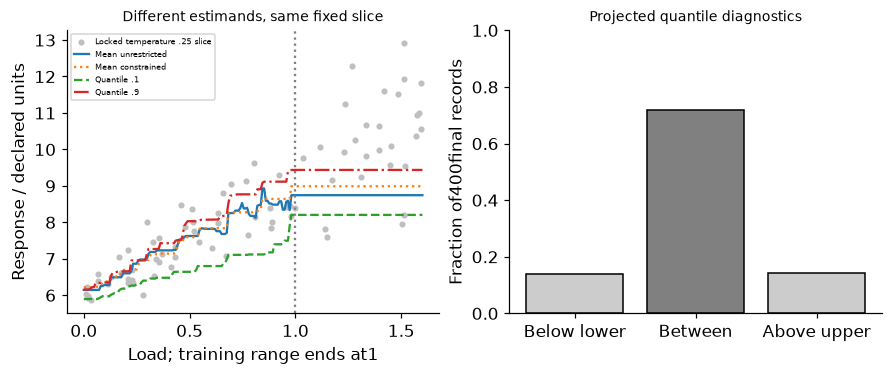

In [2]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error,mean_pinball_loss
from scipy.stats import norm
from sklearn.isotonic import IsotonicRegression
class ProjectedQuantile:
 def __init__(self,base):
  self.base=base;grid=np.linspace(0,1,201);values=base.predict(np.column_stack([grid,np.full(201,.5)]));self.raw_minimum_load_increment=float(np.diff(values).min());self.iso=IsotonicRegression(increasing=True,out_of_bounds='clip').fit(grid,values)
 def predict(self,a):
  return self.iso.predict(a[:,0])+self.base.predict(np.column_stack([np.full(len(a),.5),a[:,1]]))-self.base.predict([[.5,.5]])[0]
def generate(n,lo=0,hi=1):
 a=np.column_stack([rng.uniform(lo,hi,n),rng.uniform(0,1,n)]);mean=5+3*a[:,0]+np.sin(2*np.pi*a[:,1]);return a,mean+rng.normal(size=n)*(.2+.8*a[:,0])
X,y=generate(500);Xd,yd=generate(160);Xt,yt=generate(400);Xf,yf=generate(60,1.2,1.6);spec=[('Mean unrestricted',None,False),('Mean constrained',None,True),('Quantile .1',.1,True),('Quantile .9',.9,True)];fits={};rows=[]
for name,q,constrained in spec:
 choices=[]
 for leaves in [7,15]:
  model=HistGradientBoostingRegressor(loss='squared_error' if q is None else 'quantile',quantile=q,max_iter=120,learning_rate=.08,max_leaf_nodes=leaves,min_samples_leaf=15,early_stopping=False,monotonic_cst=[1,0] if constrained else None,interaction_cst=[{0},{1}] if constrained else None,random_state=SEED).fit(X,y)
  if q is not None:model=ProjectedQuantile(model)
  prediction=model.predict(Xd);score=float(mean_squared_error(yd,prediction) if q is None else mean_pinball_loss(yd,prediction,alpha=q));choices.append((score,leaves,model))
 score,leaves,model=min(choices,key=lambda r:r[0]);fits[name]=model;p=model.predict(Xt);f=model.predict(Xf);row={'model':name,'development_selection_loss':'squared error' if q is None else f'pinball{q}','selected_max_leaf_nodes':leaves,'development_loss':score,'final_mse':float(mean_squared_error(yt,p)),'future_mse':float(mean_squared_error(yf,f)),'constrained':constrained}
 if q is not None:row.update({'training_model_only_projection':True,'raw_201point_minimum_load_increment':model.raw_minimum_load_increment,'quantile':q,'final_pinball':float(mean_pinball_loss(yt,p,alpha=q)),'final_fraction_below':float(np.mean(yt<=p)),'future_pinball':float(mean_pinball_loss(yf,f,alpha=q))})
 rows.append(row)
lower=fits['Quantile .1'].predict(Xt);upper=fits['Quantile .9'].predict(Xt);assert lower.shape==upper.shape==(400,);RESULTS['fits']=rows;RESULTS['roles']={'training':500,'development':160,'final':400,'future_load_final':60};RESULTS['interval_diagnostics']={'nominal_central_mass':.8,'projected_final_coverage_no_recalibration':float(np.mean((yt>=lower)&(yt<=upper))),'crossing_rows':int(np.sum(lower>upper)),'upper_exceedance_fraction':float(np.mean(yt>upper)),'final_repair_or_recalibration':False}
# Fixed temperature slice shares observations/predictions, avoiding a mixed-temperature curve.
grid=np.column_stack([np.linspace(0,1.6,200),np.full(200,.25)]);slice_x=np.column_stack([rng.uniform(0,1.6,80),np.full(80,.25)]);slice_y=5+3*slice_x[:,0]+1+rng.normal(size=80)*(.2+.8*slice_x[:,0]);fig,axes=plt.subplots(1,2,figsize=(8,3.3));axes[0].scatter(slice_x[:,0],slice_y,s=9,color='.75',label='Locked temperature .25 slice')
for name,style in [('Mean unrestricted','-'),('Mean constrained',':'),('Quantile .1','--'),('Quantile .9','-.')]:axes[0].plot(grid[:,0],fits[name].predict(grid),style,label=name)
axes[0].axvline(1,color='.5',ls=':');axes[0].set(xlabel='Load; training range ends at1',ylabel='Response / declared units',title='Different estimands, same fixed slice');axes[0].legend(fontsize=5);axes[1].bar(['Below lower','Between','Above upper'],[np.mean(yt<lower),np.mean((yt>=lower)&(yt<=upper)),np.mean(yt>upper)],color=['.8','.5','.8'],edgecolor='black');axes[1].set(ylabel='Fraction of400final records',ylim=(0,1),title='Projected quantile diagnostics');plt.show()


<a id="audit"></a>
## Check constraints and a defined stored-array budget

Evaluate load monotonicity over81load-grid points at five fixed temperatures. For the constrained mean and explicitly projected quantile candidates, a four-corner contrast must vanish within numerical tolerance under their additive forms. Raw quantile monotonicity failures remain recorded in the fitting report. A passed finite grid is an implementation diagnostic in addition to the estimator's declared constraint, not a proof that the observed response is physically monotone. Inspect the pinned1.9.0 private tree-node storage to count node-array bytes and nodes/leaves; this ledger excludes bin thresholds, Python objects, arrays elsewhere and complete process RSS. Record120prediction trees and leaf counts plus the isotonic threshold arrays, without claiming a measured latency ordering. The native quantile leaf-update behavior was inspected in the installed1.9.0 source; the failed grid audit is direct execution evidence, not a claim about all versions. Quantile predictions do not define a full outcome distribution or an interval for the model's conditional mean.


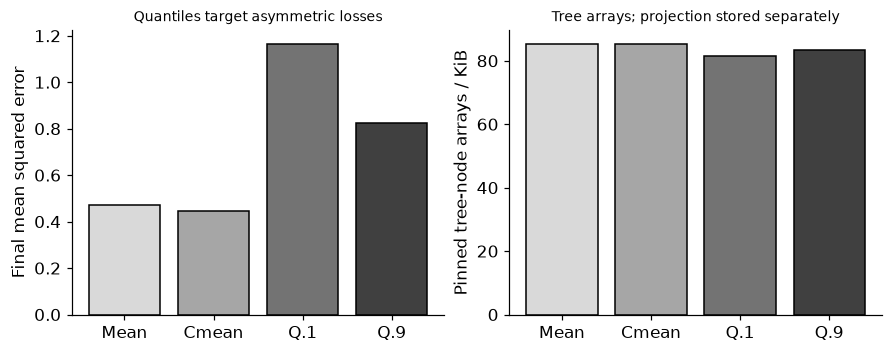

In [3]:
constraint_rows=[];cost=[]
for name,model in fits.items():
 minimum=min(float(np.diff(model.predict(np.column_stack([np.linspace(0,1.6,81),np.full(81,t)]))).min()) for t in np.linspace(0,1,5));corners=np.array([[.2,.2],[.8,.2],[.2,.8],[.8,.8]]);v=model.predict(corners);contrast=float(v[0]+v[3]-v[1]-v[2]);constrained=name!='Mean unrestricted'
 if constrained:assert minimum>=-1e-10;np.testing.assert_allclose(contrast,0,atol=1e-10)
 constraint_rows.append({'model':name,'constrained':constrained,'minimum_grid_load_increment':minimum,'four_corner_interaction_contrast':contrast});base=model.base if isinstance(model,ProjectedQuantile) else model;nodes=[tree.nodes for stage in base._predictors for tree in stage];cost.append({'model':name,'prediction_trees':len(nodes),'nodes':sum(len(v) for v in nodes),'leaves':sum(int(v['is_leaf'].sum()) for v in nodes),'private_node_array_bytes':sum(v.nbytes for v in nodes),'projection_threshold_array_bytes':int(model.iso.X_thresholds_.nbytes+model.iso.y_thresholds_.nbytes) if isinstance(model,ProjectedQuantile) else 0,'excludes':'bin mapper, Python/library overhead, other arrays, complete process RSS'})
assert all(c['prediction_trees']==120 for c in cost);RESULTS['constraints']=constraint_rows;RESULTS['stored_node_arrays']=cost;RESULTS['locked_slice']={'rows':80,'temperature':.25,'used_for_selection':False};fig,axes=plt.subplots(1,2,figsize=(8,3.1));pos=np.arange(4);axes[0].bar(pos,[r['final_mse'] for r in rows],color=['.85','.65','.45','.25'],edgecolor='black');axes[0].set(xticks=pos,xticklabels=['Mean','Cmean','Q.1','Q.9'],ylabel='Final mean squared error',title='Quantiles target asymmetric losses');axes[1].bar(pos,[c['private_node_array_bytes']/1024 for c in cost],color=['.85','.65','.45','.25'],edgecolor='black');axes[1].set(xticks=pos,xticklabels=['Mean','Cmean','Q.1','Q.9'],ylabel='Pinned tree-node arrays / KiB',title='Tree arrays; projection stored separately');plt.show()


In [4]:
summary={'example_id':'code_092','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['monotonic and additive interaction constraints', 'separate mean and quantile loss targets', 'coverage crossings and support challenges', 'version-specific tree-array resource ledger'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["monotonic and additive interaction constraints", "separate mean and quantile loss targets", "coverage crossings and support challenges", "version-specific tree-array resource ledger"], "elapsed_seconds": 0.624, "example_id": "code_092", "hardware": "Darwin arm64 CPU", "results": {"constraints": [{"constrained": false, "four_corner_interaction_contrast": -0.4417414775267643, "minimum_grid_load_increment": -0.4409037444949808, "model": "Mean unrestricted"}, {"constrained": true, "four_corner_interaction_contrast": 1.7763568394002505e-15, "minimum_grid_load_increment": 0.0, "model": "Mean constrained"}, {"constrained": true, "four_corner_interaction_contrast": 0.0, "minimum_grid_load_increment": 0.0, "model": "Quantile .1"}, {"constrained": true, "four_corner_interaction_contrast": -8.881784197001252e-16, "minimum_grid_load_increment": 0.0, "model": "Quantile .9"}], "fits": [{"constrained": false, "development_loss": 0.5347948631445805, "